# Experiment - 100 Epochs

## Data

In [1]:
import pandas as pd

mnist_train = pd.read_csv("mnist_train.csv", header=None)
mnist_test = pd.read_csv("mnist_test.csv", header=None)

mnist = pd.concat([mnist_train, mnist_test], ignore_index=True)

X_train = mnist_train.loc[:, mnist_train.columns[1:]].to_numpy()
y_train = mnist_train.loc[:, mnist_train.columns[0]].to_numpy()

X_test = mnist_test.loc[:, mnist_test.columns[1:]].to_numpy()
y_test = mnist_test.loc[:, mnist_test.columns[0]].to_numpy()

In [2]:
mnist

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69996,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69997,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
69998,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


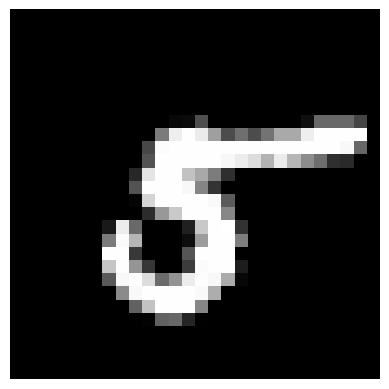

<Figure size 640x480 with 0 Axes>

In [3]:
from utils import display_digit

display_digit(mnist, 69998)

## Model

In [4]:
import torch.nn as nn

class Model(nn.Module):

    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(28 * 28, 128), nn.ReLU(), nn.Linear(128, 10))
        
    def forward(self, x):
        return self.network(x)

In [5]:
from neural_network import MNISTClassifier

mnist_classifier = MNISTClassifier(Model(), lr=0.001, epochs=200, batch_size=32)
mnist_classifier.fit(X_train, y_train)
print("---")

---


## Evaluation

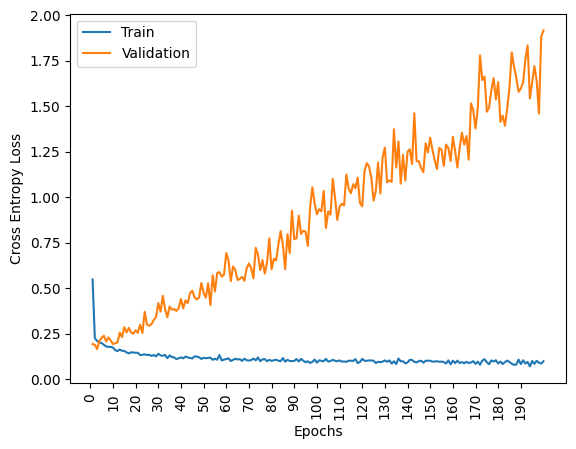

<Figure size 640x480 with 0 Axes>

In [6]:
from utils import display_losses

display_losses(mnist_classifier.train_losses, mnist_classifier.val_losses)

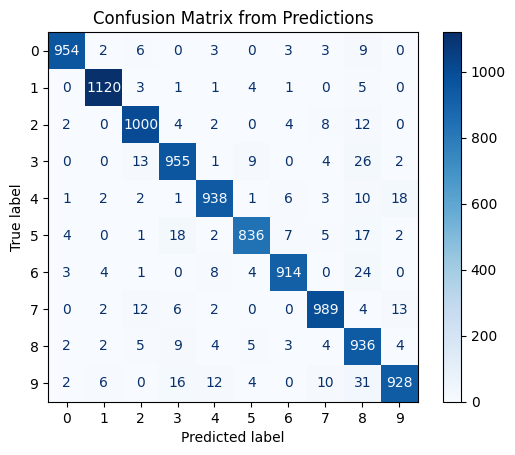

<Figure size 640x480 with 0 Axes>

In [7]:
from utils import display_confusion_matrix

y_pred = mnist_classifier.predict(X_test)
display_confusion_matrix(y_test, y_pred)

In [8]:
from sklearn.metrics import accuracy_score

print("Train Accuracy: ", accuracy_score(y_train, mnist_classifier.predict(X_train)))
print("Test Accuracy: ", accuracy_score(y_test, y_pred))

Train Accuracy:  0.98405
Test Accuracy:  0.957


Layer: network.0.weight | Shape: torch.Size([128, 784])


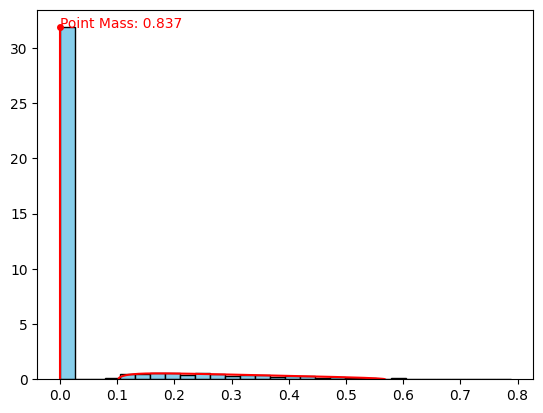

Layer: network.2.weight | Shape: torch.Size([10, 128])


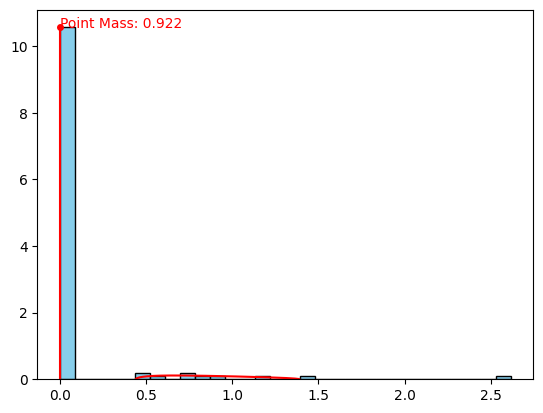

<Figure size 640x480 with 0 Axes>

In [9]:
from utils import analyze_weight_matrices

analyze_weight_matrices(mnist_classifier.model)